# Aula 02 — Datasets

Um arquivo com **891 passageiros do Titanic**. Cada linha é uma pessoa que embarcou,
e uma das colunas diz se ela sobreviveu.

Hoje a gente arranca deste arquivo tudo o que ele tem para contar: quem tinha chance,
quem não tinha, e por quê. Rode as células na ordem, comigo.

---

### As dez palavras que vão aparecer o tempo todo

Você não precisa decorar nada disto agora. Volte aqui quando bater a dúvida.

| Palavra | O que quer dizer |
|---|---|
| **DataFrame** (`df`) | a tabela dentro do Python: linhas e colunas, como uma planilha |
| `df["Age"]` | uma coluna inteira |
| **`groupby("Sex")`** | separa as linhas em grupos e faz a conta dentro de cada grupo — é o `GROUP BY` do SQL |
| **`pivot_table`** | um groupby de **duas** colunas ao mesmo tempo: uma vira linha, a outra vira coluna |
| **taxa** | a média de uma coluna de 0 e 1. `[0,1,1,0,1]` soma 3, dividido por 5 = **0,6** = 60% |
| **mediana** | o valor do meio quando você ordena. Em `7, 8, 10, 12, 500`: média 107, mediana **10** |
| **n** | quantas linhas entraram naquela conta |
| **imputar** | preencher um valor que faltava, chutando com critério |
| **contínua** | número que assume muitos valores (idade, tarifa). Oposto: contagem (0, 1, 2 filhos) |
| **cardinalidade** | quantos valores diferentes uma coluna tem. "Alta" = muitos, como nome |

E uma conversão que aparece a toda hora: **`0,384` é o mesmo que `38,4%`** — multiplique por 100.

---
## 1 · Abrir o arquivo

Se alguma biblioteca faltar, rode a célula abaixo uma vez. Se já estiver tudo instalado,
ela não faz nada.

In [1]:
# %pip install pandas matplotlib seaborn      ← tire o # e rode, se der ModuleNotFoundError

In [2]:
import pandas as pd
from pathlib import Path

# procura o titanic.csv na pasta do notebook; se não achar, baixa da internet
caminho = Path("dados/titanic.csv")
if caminho.exists():
    df = pd.read_csv(caminho)
else:
    print("dados/titanic.csv não encontrado aqui — baixando da internet")
    df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Pronto: o arquivo virou uma **tabela**, e agora dá para perguntar coisas a ele.

Duas perguntas antes de qualquer outra coisa: **qual o tamanho** e **o que está faltando**.

In [3]:
print("linhas e colunas:", df.shape)

df.info()

linhas e colunas: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


891 passageiros, 12 colunas. Repare na coluna do meio, `Non-Null Count`:

| Coluna | Preenchidas | Faltando |
|---|---|---|
| `Age` | 714 | **177** (20%) |
| `Cabin` | 204 | **687** (77%) |
| `Embarked` | 889 | 2 |

Guarde o `Cabin`. Uma coluna 77% vazia parece lixo — e é o achado mais surpreendente
do dia.

---
## 2 · O que cada coluna quer dizer

| Coluna | Significa |
|---|---|
| `Survived` | **0 = morreu · 1 = sobreviveu** |
| `Pclass` | classe do bilhete: 1ª, 2ª ou 3ª |
| `Name`, `Sex`, `Age` | nome completo, sexo, idade em anos |
| `SibSp` | irmãos e cônjuges a bordo |
| `Parch` | pais e filhos a bordo |
| `Ticket`, `Fare` | código do bilhete e o valor pago, em libras de 1912 |
| `Cabin` | número da cabine |
| `Embarked` | porto: **C** Cherbourg · **Q** Queenstown · **S** Southampton |

---
## 3 · Quem sobreviveu?

Antes de qualquer conta: as 891 pessoas do arquivo, uma por ponto.

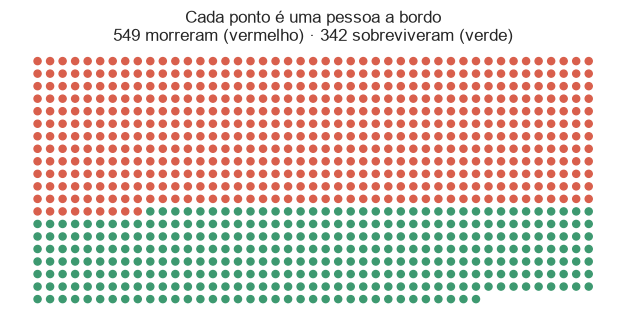

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

ordenado = df.sort_values("Survived")
cores = ordenado["Survived"].map({0: "#d95f4c", 1: "#3d9970"})

colunas = 45
x = [i % colunas for i in range(len(ordenado))]
y = [-(i // colunas) for i in range(len(ordenado))]

plt.figure(figsize=(9.5, 3.4))
plt.scatter(x, y, c=cores, s=26)
plt.gca().set_aspect("equal")
plt.axis("off")
plt.grid(False)
plt.title("Cada ponto é uma pessoa a bordo\n549 morreram (vermelho) · 342 sobreviveram (verde)")
plt.show()

### Por que a média de uma coluna de 0 e 1 é uma taxa

Cinco passageiros: `[0, 1, 1, 0, 1]`. Soma = **3**. Dividido por 5 = **0,6**.
Três dos cinco sobreviveram — e 0,6 é exatamente isso: **60%**.

É por isso que `df["Survived"].mean()` responde "quantos por cento sobreviveram". O truque
vale para qualquer coluna de sim/não.

In [5]:
exemplo = pd.Series([0, 1, 1, 0, 1])
print("soma:", exemplo.sum(), "· quantidade:", len(exemplo), "· média:", exemplo.mean())

soma: 3 · quantidade: 5 · média: 0.6


In [6]:
print("sobreviveram:", df["Survived"].mean().round(3))

print("\npor sexo:")
print(df.groupby("Sex")["Survived"].mean().round(3))

print("\npor classe:")
print(df.groupby("Pclass")["Survived"].mean().round(3))

sobreviveram: 0.384

por sexo:
Sex
female    0.742
male      0.189
Name: Survived, dtype: float64

por classe:
Pclass
1    0.630
2    0.473
3    0.242
Name: Survived, dtype: float64


No geral, 38%. Mas **74% das mulheres** contra **19% dos homens**. E 63% na 1ª classe
contra 24% na 3ª.

Em gráfico:

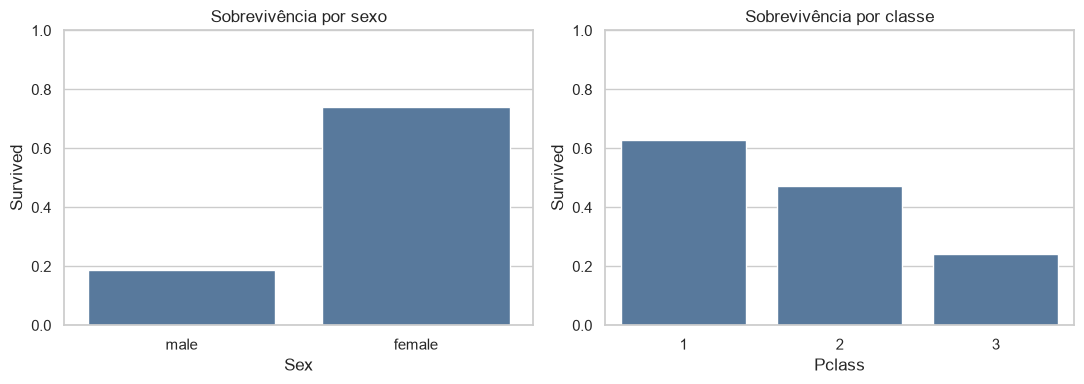

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))

sns.barplot(df, x="Sex", y="Survived", errorbar=None, color="#4c78a8", ax=eixos[0])
eixos[0].set_title("Sobrevivência por sexo")
eixos[0].set_ylim(0, 1)

sns.barplot(df, x="Pclass", y="Survived", errorbar=None, color="#4c78a8", ax=eixos[1])
eixos[1].set_title("Sobrevivência por classe")
eixos[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

Sexo e classe, cada um por vez, já dizem muito. **Cruzar os dois** diz quase tudo.

In [8]:
cruzado = pd.pivot_table(df, values="Survived", index="Sex", columns="Pclass", aggfunc="mean")
cruzado.round(3)

Pclass,1,2,3
Sex,,,
female,0.968,0.921,0.500
male,0.369,0.157,0.135


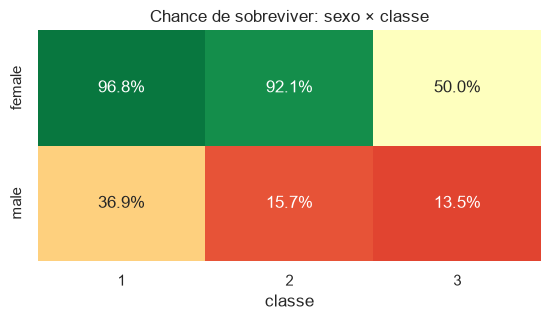

In [9]:
plt.figure(figsize=(6.5, 3))
sns.heatmap(cruzado, annot=True, fmt=".1%", cmap="RdYlGn", vmin=0, vmax=1, cbar=False)
plt.title("Chance de sobreviver: sexo × classe")
plt.ylabel(""); plt.xlabel("classe")
plt.show()

**Mulher na 1ª classe: 96,8%. Homem na 3ª: 13,5%.** Sete vezes de diferença.

Este é o achado central do dataset — e saiu de duas linhas de código.

✋ **Sua vez.** Complete os `___` e rode. A pergunta: o **porto de embarque** muda a chance?

In [10]:
# ✋ sua vez — escreva o nome da coluna entre as aspas e rode de novo
coluna = ""        # dica: é a coluna do porto de embarque

if coluna:
    display(pd.pivot_table(df, values="Survived", index=coluna,
                           columns="Pclass", aggfunc="mean").round(3))
    print("\nquanta gente embarcou em cada porto:")
    display(df[coluna].value_counts())
else:
    print("preencha a variável 'coluna' na linha 2 e rode a célula de novo")

preencha a variável 'coluna' na linha 2 e rode a célula de novo


---
## 4 · Criança tinha mais chance?

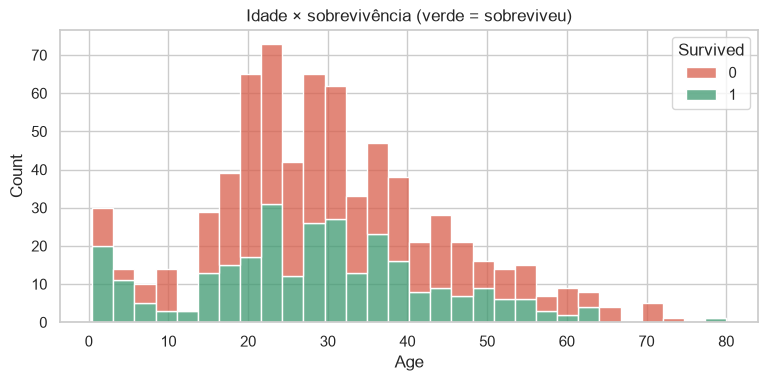

In [7]:
plt.figure(figsize=(9, 3.8))
sns.histplot(df, x="Age", hue="Survived", multiple="stack", bins=30,
             palette=["#d95f4c", "#3d9970"])
plt.title("Idade × sobrevivência (verde = sobreviveu)")
plt.show()

Olhe a ponta esquerda: é o **único** trecho do gráfico em que o verde domina.

Para medir isso, corte a idade em faixas.

In [8]:
df["Faixa"] = pd.cut(df["Age"],
                     bins=[0, 12, 18, 35, 60, 100],
                     labels=["criança", "adolescente", "adulto jovem", "adulto", "idoso"])

df.groupby("Faixa", observed=True)["Survived"].agg(pessoas="count", taxa="mean").round(3)

,pessoas,taxa
Faixa,,
criança,69,0.580
adolescente,70,0.429
adulto jovem,358,0.383
adulto,195,0.400
idoso,22,0.227


Crianças até 12 anos: **58%**, bem acima dos 38% gerais. Idosos: 23%.

E os dois extremos do navio, para lembrar que dado é gente:

In [13]:
print("o mais velho a bordo:")
print(df.nlargest(1, "Age")[["Name", "Age", "Pclass", "Survived"]].to_string(index=False))

print("\no mais novo a bordo:")
print(df.nsmallest(1, "Age")[["Name", "Age", "Pclass", "Survived"]].to_string(index=False))

o mais velho a bordo:
                                Name  Age  Pclass  Survived
Barkworth, Mr. Algernon Henry Wilson 80.0       1         1

o mais novo a bordo:
                           Name  Age  Pclass  Survived
Thomas, Master. Assad Alexander 0.42       3         1


Um senhor de **80 anos** na 1ª classe: sobreviveu. Um bebê de **5 meses** (0,42 ano)
na 3ª classe: sobreviveu também.

---
## 5 · O preço do bilhete

Antes, com cinco números na mão. **Média** é a soma dividida pela quantidade. **Mediana** é
o valor do meio, depois de ordenar.

In [14]:
tarifas = pd.Series([7, 8, 10, 12, 500])
print("média  :", tarifas.mean(), "  ← um único valor de 500 arrastou a média")
print("mediana:", tarifas.median(), "   ← o do meio não se mexeu")

média  : 107.4   ← um único valor de 500 arrastou a média
mediana: 10.0    ← o do meio não se mexeu


Agora no Titanic inteiro:

In [15]:
print("média  :", round(df["Fare"].mean(), 2))
print("mediana:", round(df["Fare"].median(), 2))
print("máximo :", round(df["Fare"].max(), 2))

média  : 32.2
mediana: 14.45
máximo : 512.33


A média (**32,20**) é mais que o **dobro** da mediana (**14,45**).

Isso significa sempre a mesma coisa: **poucos valores altíssimos puxando a média para
cima**. Metade do navio pagou menos de £14,45 — e alguém pagou £512.

Quando média e mediana se afastam assim, a média não descreve ninguém: nem o pobre,
nem o rico.

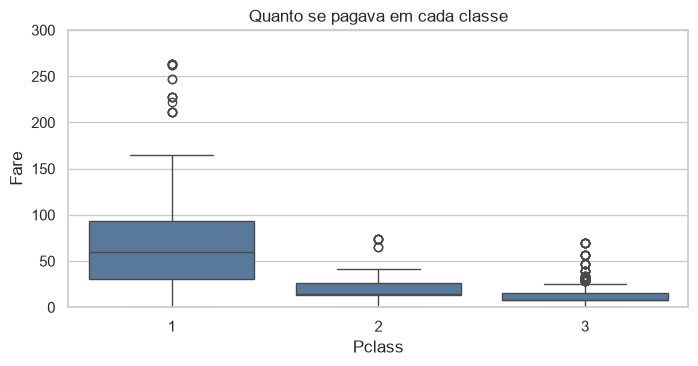

In [9]:
plt.figure(figsize=(8, 3.6))
sns.boxplot(df, x="Pclass", y="Fare", color="#4c78a8")
plt.title("Quanto se pagava em cada classe")
plt.ylim(0, 300)   # sem isso, os três bilhetes de £512 achatam o resto do gráfico
plt.show()

In [17]:
df.nlargest(5, "Fare")[["Name", "Sex", "Age", "Pclass", "Fare", "Survived"]]

,Name,Sex,Age,Pclass,Fare,Survived
258,"Ward, Miss. Anna",female,35.0,1,512.3292,1
679,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,1,512.3292,1
737,"Lesurer, Mr. Gustave J",male,35.0,1,512.3292,1
27,"Fortune, Mr. Charles Alexander",male,19.0,1,263.0000,0
88,"Fortune, Miss. Mabel Helen",female,23.0,1,263.0000,1


Os três bilhetes mais caros do navio — £512,33, mais de trinta vezes a tarifa mediana —
**e os três sobreviveram**.

Idade e dinheiro, juntos, no mesmo gráfico:

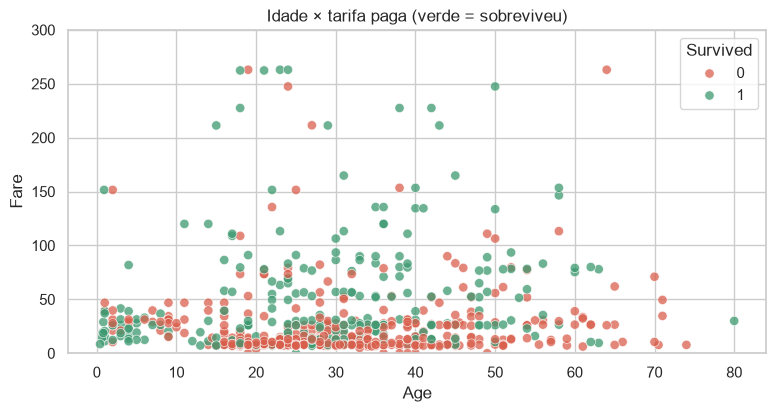

In [18]:
plt.figure(figsize=(9, 4.2))
sns.scatterplot(df, x="Age", y="Fare", hue="Survived",
                palette=["#d95f4c", "#3d9970"], alpha=0.75, s=45)
plt.ylim(0, 300)
plt.title("Idade × tarifa paga (verde = sobreviveu)")
plt.show()

A faixa de baixo — quem pagou até £50 — é um tapete vermelho, em qualquer idade. Acima
de £100 o verde domina. Em números:

In [19]:
faixa_tarifa = pd.cut(df["Fare"], [0, 50, 100, 600], include_lowest=True)

df.groupby(faixa_tarifa, observed=True)["Survived"].agg(pessoas="count", taxa="mean").round(3)

,pessoas,taxa
Fare,,
"(-0.001, 50.0]",731,0.319
"(50.0, 100.0]",107,0.654
"(100.0, 600.0]",53,0.736


**32% contra 74%.** E repare onde está a multidão: 731 das 891 pessoas pagaram até £50.
**Dinheiro comprava chance de sobreviver** — o gráfico mostrou, a tabela mediu.

---
## 6 · O que está escondido dentro do nome

Olhe um nome qualquer: `Braund, Mr. Owen Harris`. Entre a vírgula e o ponto tem um
**título social**: Mr, Miss, Mrs, Master. Dá para arrancar isso e virar uma coluna nova.

In [20]:
df["Titulo"] = df["Name"].str.extract(r",\s*([^\.]+)\.")

df["Titulo"].value_counts().head(6)

Titulo
Mr        517
Miss      182
Mrs       125
Master     40
Dr          7
Rev         6
Name: count, dtype: int64

In [21]:
(df.groupby("Titulo")["Survived"]
   .agg(pessoas="count", taxa="mean")
   .sort_values("pessoas", ascending=False)
   .head(6).round(3))

,pessoas,taxa
Titulo,,
Mr,517,0.157
Miss,182,0.698
Mrs,125,0.792
Master,40,0.575
Dr,7,0.429
Rev,6,0.000


`Mr`: 517 homens, **16%** de sobrevivência. `Mrs`: **79%**.

E repare no `Master`: 40 pessoas, **57%**. Por quê?

In [22]:
df.groupby("Titulo")["Age"].median().sort_values().head(4)

Titulo
Master     3.5
Miss      21.0
Mme       24.0
Mlle      24.0
Name: Age, dtype: float64

**"Master", no inglês de 1912, era como se chamava um menino.** Mediana de idade:
**3,5 anos**.

O dataset nunca teve uma coluna "é criança" — mas a informação estava lá o tempo todo,
escondida no meio do nome. Criar a coluna que faltava a partir das que existem tem
nome: *feature engineering*.

---
## 7 · Sozinho ou com a família?

`SibSp` (irmãos e cônjuges) + `Parch` (pais e filhos) + a própria pessoa = tamanho da
família a bordo.

In [23]:
df["Familia"] = df["SibSp"] + df["Parch"] + 1

df.groupby("Familia")["Survived"].agg(pessoas="count", taxa="mean").round(3)

,pessoas,taxa
Familia,,
1,537,0.304
2,161,0.553
3,102,0.578
4,29,0.724
5,15,0.200
6,22,0.136
7,12,0.333
8,6,0.000
11,7,0.000


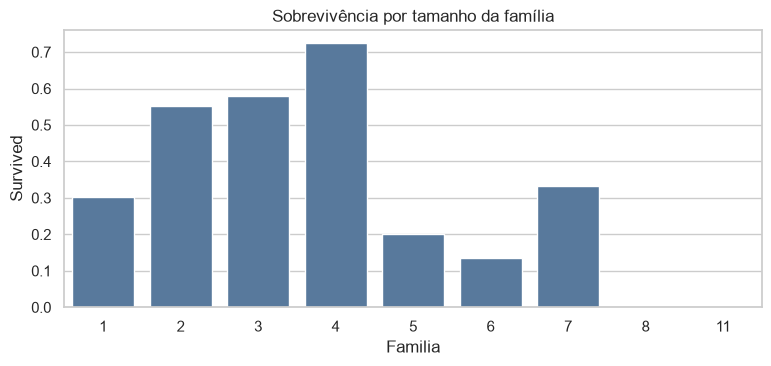

In [24]:
plt.figure(figsize=(9, 3.6))
sns.barplot(df, x="Familia", y="Survived", errorbar=None, color="#4c78a8")
plt.title("Sobrevivência por tamanho da família")
plt.show()

Sobe até **4 pessoas** (72%) e despenca depois. Família pequena ajuda; família grande
atrapalha — provavelmente porque ninguém abandona ninguém.

**Mas olhe a coluna `pessoas`**: a família de 8 tem 6 casos, a de 11 tem 7. Taxa
calculada sobre 6 pessoas não é achado, é ruído. Toda vez que vir uma taxa, pergunte:
*sobre quantos casos?*

E o caso mais duro do arquivo:

In [25]:
df[df["Name"].str.startswith("Sage,")][["Name", "Age", "Ticket", "Pclass", "Survived"]]

,Name,Age,Ticket,Pclass,Survived
159,"Sage, Master. Thomas Henry",NaN,CA. 2343,3,0
180,"Sage, Miss. Constance Gladys",NaN,CA. 2343,3,0
201,"Sage, Mr. Frederick",NaN,CA. 2343,3,0
324,"Sage, Mr. George John Jr",NaN,CA. 2343,3,0
792,"Sage, Miss. Stella Anna",NaN,CA. 2343,3,0
846,"Sage, Mr. Douglas Bullen",NaN,CA. 2343,3,0
863,"Sage, Miss. Dorothy Edith ""Dolly""",NaN,CA. 2343,3,0


Sete integrantes da família **Sage**, todos no mesmo bilhete `CA. 2343`, 3ª classe.
**Nenhum sobreviveu.** Nenhuma idade registrada.

---
## 8 · A coluna 77% vazia que era ouro

`Cabin` está vazia em 687 das 891 linhas. O reflexo é apagar a coluna.

Antes disso: e se **o próprio fato de estar vazia** disser alguma coisa?

In [26]:
df["tem_cabine"] = df["Cabin"].notna()

df.groupby("tem_cabine")["Survived"].agg(pessoas="count", taxa="mean").round(3)

,pessoas,taxa
tem_cabine,,
False,687,0.300
True,204,0.667


**30% contra 67%.** Quem tinha número de cabine registrado sobreviveu **mais que o
dobro**.

O vazio não era aleatório: a cabine não era anotada para quem viajava na 3ª classe.
A ausência do dado *era* o dado. Um `dropna()` distraído teria apagado isso.

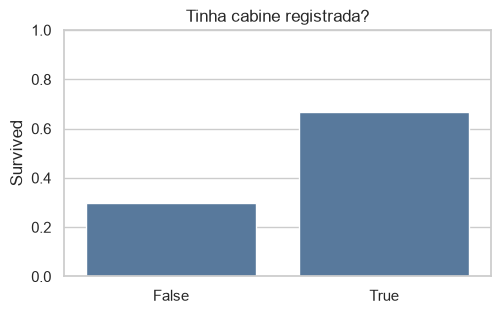

In [27]:
plt.figure(figsize=(5.5, 3.2))
sns.barplot(df, x="tem_cabine", y="Survived", errorbar=None, color="#4c78a8")
plt.title("Tinha cabine registrada?")
plt.xlabel(""); plt.ylim(0, 1)
plt.show()

E dá para arrancar mais uma coisa dessa coluna: a **letra** da cabine é o deck do navio.
`C85` é o deck C. Deck A era o mais alto; G, o mais fundo.

In [28]:
df["Deck"] = df["Cabin"].str[0]

por_deck = (df.dropna(subset=["Deck"])
              .groupby("Deck")["Survived"]
              .agg(pessoas="count", taxa="mean").round(3))
por_deck

,pessoas,taxa
Deck,,
A,15,0.467
B,47,0.745
C,59,0.593
D,33,0.758
E,32,0.750
F,13,0.615
G,4,0.500
T,1,0.000


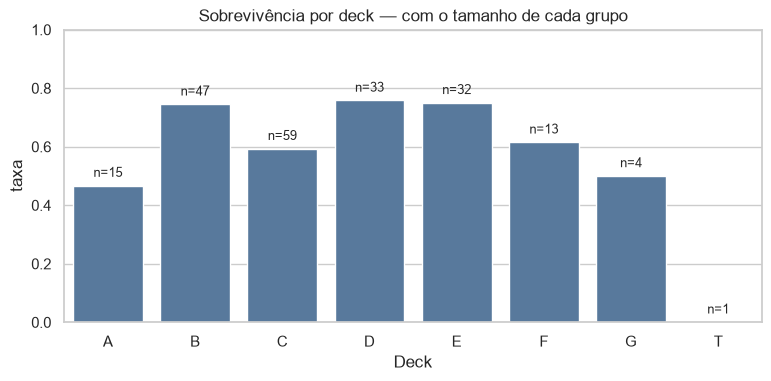

In [29]:
plt.figure(figsize=(9, 3.8))
eixo = sns.barplot(por_deck.reset_index(), x="Deck", y="taxa", color="#4c78a8")
for i, (pessoas, taxa) in enumerate(zip(por_deck["pessoas"], por_deck["taxa"])):
    eixo.text(i, taxa + 0.03, f"n={pessoas}", ha="center", fontsize=9)
plt.ylim(0, 1)
plt.title("Sobrevivência por deck — com o tamanho de cada grupo")
plt.show()

Parece que os decks B, D e E salvavam mais... até você ler o `n` em cima das barras.
O deck **T tem uma única pessoa**, e o **G tem quatro**. Aquela barra no chão não é um
achado sobre o deck T: é uma pessoa.

**Toda taxa é a taxa de um grupo — e grupo pequeno não sustenta conclusão nenhuma.**

✋ **Sua vez.** O mesmo teste, agora com a **idade**: quem não teve a idade registrada
sobreviveu mais ou menos? Complete e rode.

In [30]:
# ✋ sua vez — escreva o nome da coluna entre as aspas e rode de novo
coluna = ""        # dica: é a coluna da idade

if coluna:
    display(df.groupby(df[coluna].isna())["Survived"]
              .agg(pessoas="count", taxa="mean").round(3))
else:
    print("preencha a variável 'coluna' na linha 2 e rode a célula de novo")

preencha a variável 'coluna' na linha 2 e rode a célula de novo


---
## 9 · E as 177 idades que faltam?

Três saídas, três consequências:

| Opção | O que acontece |
|---|---|
| **A** · jogar as linhas fora | perde 20% do dataset — e não ao acaso |
| **B** · preencher tudo com a média (29,7) | dá 29,7 anos a cada bebê |
| **C** · preencher com a mediana **do título** | respeita o grupo: Master vira 3,5 |

A opção C é a boa — e agora é fácil, porque a coluna `Titulo` já existe.

In [31]:
# ⚠️ esta célula MUDA a coluna Age para sempre. Se você rodar as células do § 4 de novo
#    depois daqui, os números vão sair diferentes — e está certo que saiam.
df["Age"] = df["Age"].fillna(df.groupby("Titulo")["Age"].transform("median"))

print("idades faltando agora:", df["Age"].isna().sum())
print("idade média dos 'Master':", round(df.loc[df["Titulo"] == "Master", "Age"].mean(), 1))

idades faltando agora: 0
idade média dos 'Master': 4.5


As três opções lado a lado, no mesmo gráfico — para você ver o que cada escolha faz com
os dados:

In [32]:
descartar = df["Age"].dropna()
media     = df["Age"].fillna(df["Age"].mean())
por_titulo = df["Age"].fillna(df.groupby("Titulo")["Age"].transform("median"))

comparacao = pd.DataFrame({
    "A · descartar":       descartar.describe()[["count", "mean", "std"]],
    "B · média":           media.describe()[["count", "mean", "std"]],
    "C · mediana/título":  por_titulo.describe()[["count", "mean", "std"]],
}).round(2)
comparacao

,A · descartar,B · média,C · mediana/título
count,891.00,891.00,891.00
mean,29.39,29.39,29.39
std,13.27,13.27,13.27


Olhe a linha `std` (o quanto as idades variam entre si). A opção **B** achata: 177 pessoas
recebendo o mesmo número reduz a variação artificialmente. A **C** também achata um pouco,
mas menos, porque distribui em quatro ou cinco valores diferentes.

Nenhuma é "a certa" — cada uma é uma **hipótese**, e no relatório do projeto ela vai escrita
e justificada.

---
## 10 · O painel

Tudo o que a gente descobriu, em quatro gráficos.

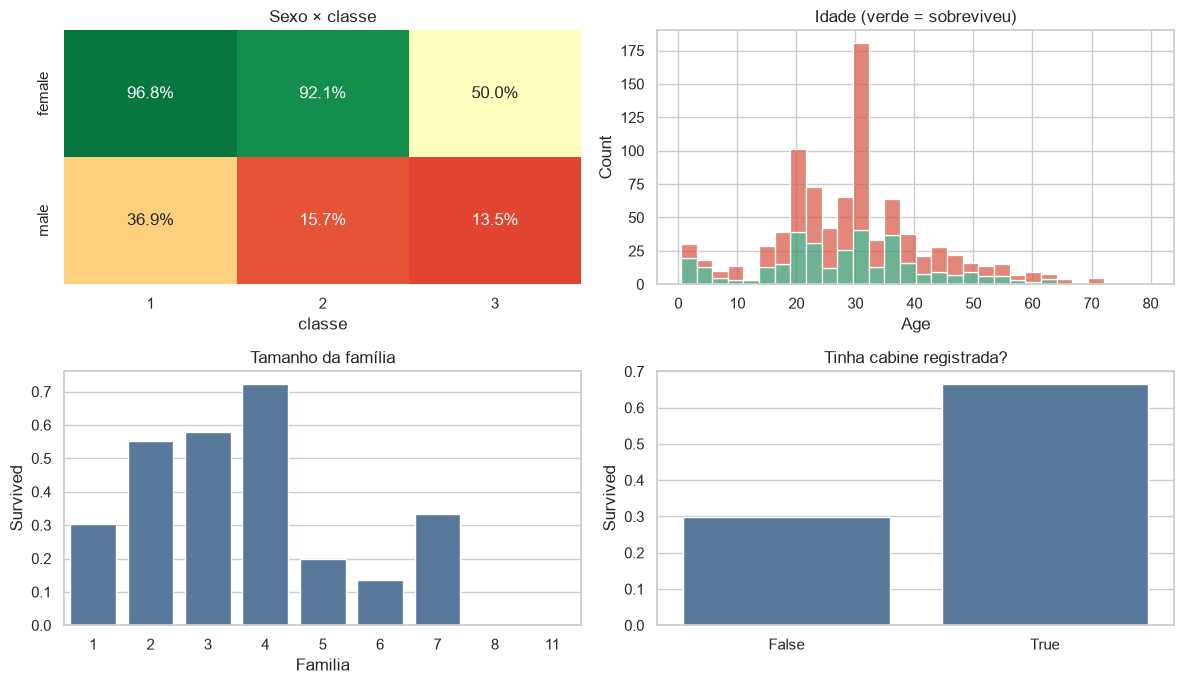

In [33]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))

sns.heatmap(cruzado, annot=True, fmt=".1%", cmap="RdYlGn", vmin=0, vmax=1,
            cbar=False, ax=ax[0][0])
ax[0][0].set_title("Sexo × classe"); ax[0][0].set_ylabel(""); ax[0][0].set_xlabel("classe")

sns.histplot(df, x="Age", hue="Survived", multiple="stack", bins=30,
             palette=["#d95f4c", "#3d9970"], legend=False, ax=ax[0][1])
ax[0][1].set_title("Idade (verde = sobreviveu)")

sns.barplot(df, x="Familia", y="Survived", errorbar=None, color="#4c78a8", ax=ax[1][0])
ax[1][0].set_title("Tamanho da família")

sns.barplot(df, x="tem_cabine", y="Survived", errorbar=None, color="#4c78a8", ax=ax[1][1])
ax[1][1].set_title("Tinha cabine registrada?"); ax[1][1].set_xlabel("")

plt.tight_layout()
plt.show()

Repare no histograma de idade: ele mudou desde o § 4. Aquele pico em torno dos 30 anos
são as 177 idades que a gente preencheu no § 9 — todas caíram na mediana do seu título.
**Imputar tem custo**, e o gráfico mostra qual.

Cinco achados, **nenhum modelo de machine learning**:

1. Sexo e classe explicam quase tudo — 96,8% contra 13,5%.
2. A coluna 77% vazia era informação: 67% contra 30%.
3. Família ajuda até 4 pessoas; depois vira risco.
4. O nome carregava a idade — "Master" é menino de 3,5 anos.
5. A média da tarifa não descreve ninguém.

Tudo com `read_csv`, `groupby`, `cut` e um punhado de gráficos. **É exatamente isso
que se espera do trabalho de vocês.**

---
## 11 · E você, teria sobrevivido?

A função abaixo procura no dataset as pessoas parecidas com você e devolve a taxa
delas. Troque os valores e rode de novo.

In [34]:
def minha_chance(sexo, classe, idade):
    parecidos = df[(df["Sex"] == sexo) &
                   (df["Pclass"] == classe) &
                   (df["Age"].between(idade - 5, idade + 5))]
    if len(parecidos) == 0:
        return "ninguém parecido a bordo"
    return f"{len(parecidos)} pessoas parecidas · {parecidos['Survived'].mean():.0%} sobreviveram"


print("mulher, 1ª classe, 30 anos :", minha_chance("female", 1, 30))
print("homem,  3ª classe, 22 anos :", minha_chance("male",   3, 22))
print("homem,  1ª classe, 40 anos :", minha_chance("male",   1, 40))

mulher, 1ª classe, 30 anos : 28 pessoas parecidas · 96% sobreviveram
homem,  3ª classe, 22 anos : 108 pessoas parecidas · 14% sobreviveram
homem,  1ª classe, 40 anos : 27 pessoas parecidas · 48% sobreviveram


In [35]:
# ✋ sua vez — bote os seus dados aqui
minha_chance("male", 3, 21)

'112 pessoas parecidas · 12% sobreviveram'

## 12 · Agora o dataset do SEU projeto

O trabalho tem requisitos duros. As mesmas quatro linhas que você rodou no § 1 respondem
quase todos eles — agora aplicadas ao dataset que você está pensando em propor.

**≥ 2.000 linhas** · **≥ 10 colunas** · **≥ 3 numéricas** (uma contínua) · **≥ 3 categóricas**
(uma com mais de 5 valores) · **≥ 1 data** cobrindo 12 meses · **≥ 1 coluna de texto** ·
**≥ 1 coluna com 5% a 50% vazia**.


In [36]:
# troque pelo caminho ou pela URL do seu dataset candidato
# meu = pd.read_csv("caminho/do/seu.csv", sep=";")

# meu.shape             # linhas e colunas
# meu.dtypes            # o que é número, o que é texto
# meu.nunique()         # quantos valores diferentes por coluna
# (meu.isna().mean() * 100).round(1)   # % vazio por coluna

**O Titanic não passaria**: 891 linhas, quando o mínimo são 2.000. Ele é ótimo para aprender
e pequeno demais para o trabalho — por isso está na lista dos proibidos.


---
## Para a próxima aula — 13/08

In [37]:
tarefas = {
    "1. Fechar o grupo do projeto (até 3 pessoas)":            False,
    "2. Escolher um dataset — link e licença anotados":         False,
    "3. Conferir os mínimos: shape, dtypes, nunique, isna":     False,
    "4. Rascunhar as 3 perguntas do projeto":                   False,
    "5. ENTREGAR A LISTA 1 no AVA (vale nota)":                 False,
}

for tarefa, feito in tarefas.items():
    print(("[x] " if feito else "[ ] ") + tarefa)

print("\nTroque False por True conforme for fazendo. Tudo vence em 13/08, início da aula 3.")

[ ] 1. Fechar o grupo do projeto (até 3 pessoas)
[ ] 2. Escolher um dataset — link e licença anotados
[ ] 3. Conferir os mínimos com as quatro linhas
[ ] 4. Rascunhar as 3 perguntas do projeto
[ ] 5. ENTREGAR A LISTA 1 no AVA (vale nota)

Troque False por True conforme for fazendo. Tudo vence em 13/08, início da aula 3.


E se esquecer todo o resto, lembre de três coisas:

- Toda taxa vem acompanhada de **quantas pessoas** ela representa.
- **Vazio pode ser informação** — olhe antes de apagar.
- Todo dataset é um **recorte**: alguém decidiu o que medir, e o que ignorar.